# 2025년 시간대별 자주 출고되는 상품

커널 **Python (hit-stocks-analysis)**을 선택한 뒤 **Restart Kernel and Run All Cells**로 실행하세요.
CSV 로딩부터 집계·표·그래프·결과 저장까지 위에서 아래로 실행됩니다. Excel 저장은 잠시 시간이 걸립니다.

- **시간:** `outboundRequestDateTime`의 시(hour). 실제 출고 완료 시각은 아닙니다. 원본 시간대 정보가 없어 시차 변환 없이 사용합니다.
- **대상:** 2025년 데이터 중 `SHIPPED`, 피킹 수량 양수, 주문번호와 SKU가 있는 행.
- **순위:** 시간대·SKU별 고유 주문 수. 분할 행은 주문 수에서 중복 계산하지 않고 수량은 합산합니다.
- **동률:** 피킹 수량 내림차순, SKU 오름차순.
- **자료 범위:** 현재 파일은 **2025-08-31이 빠진 364일분**입니다. 자료 없는 날짜를 무출고로 단정하지 않습니다.

마지막 저장 셀을 실행하면 `reports/hourly_2025/`의 기존 결과를 갱신합니다.


## 1. 환경과 경로 설정

프로젝트 루트 또는 `notebooks/`에서 실행할 수 있습니다.


In [1]:
import json
import os
from pathlib import Path

current = Path.cwd().resolve()
ROOT = next(
    path
    for path in (current, *current.parents)
    if (path / "pyproject.toml").is_file() and (path / "src" / "hit_stocks_analysis").is_dir()
)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))

'/Users/hoyeonjang/MyProjects/hit-stocks-analysis/.cache'

In [2]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib import font_manager

%matplotlib inline

output = ROOT / "reports" / "hourly_2025"
output.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)
print("프로젝트:", ROOT)
print("결과 저장:", output)

프로젝트: /Users/hoyeonjang/MyProjects/hit-stocks-analysis
결과 저장: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/hourly_2025


## 2. CSV 불러오기

식별자의 선행 0을 보존하도록 문자열로 읽고, 다음 셀에서 시각과 수량을 변환합니다.


In [3]:
files = sorted(ROOT.glob("outbound_2025-*.csv"))
if not files:
    raise FileNotFoundError("프로젝트 루트에 2025년 outbound CSV가 없습니다.")
# 이 셀을 다시 실행할 때 이전 연결을 정리합니다.
if "connection" in globals():
    globals()["connection"].close()
connection = duckdb.connect()
connection.read_csv([str(path) for path in files], all_varchar=True).create_view("raw")
display(
    pd.DataFrame(
        {
            "파일": [p.name for p in files],
            "크기(MB)": [round(p.stat().st_size / 1e6, 1) for p in files],
        }
    )
)

,파일,크기(MB)
0,outbound_2025-01-01_2025-04-30_2026-04-21_1506.csv,106.7
1,outbound_2025-05-01_2025-08-30_2026-04-21_1603.csv,111.2
2,outbound_2025-09-01_2025-12-31_2026-04-21_1634.csv,112.4


## 3. 날짜·수량 변환과 분석 대상 필터

변환 실패·분석 제외 건수는 데이터 점검 셀에서 확인합니다.


In [4]:
connection.execute("""
    CREATE OR REPLACE TEMP TABLE prepared AS
    SELECT TRY_CAST(outboundRequestDateTime AS TIMESTAMP) AS requested_at,
           NULLIF(TRIM("orderId(주문번호)"), '') AS order_id,
           NULLIF(TRIM(skuCode), '') AS sku_code,
           skuName AS sku_name, status,
           TRY_CAST(pickingQuantity AS DOUBLE) AS picked_quantity
    FROM raw
""")

connection.execute("""
    CREATE OR REPLACE TEMP TABLE eligible AS
    SELECT *, EXTRACT(hour FROM requested_at)::INTEGER AS hour
    FROM prepared
    WHERE requested_at >= TIMESTAMP '2025-01-01'
      AND requested_at < TIMESTAMP '2026-01-01'
      AND status = 'SHIPPED' AND picked_quantity > 0
      AND order_id IS NOT NULL AND sku_code IS NOT NULL
""")

## 4. 시간대별 상품 순위와 전체 주문 수

상품별 주문 수는 해당 시간대의 고유 주문번호 수입니다.
`order_share_pct`는 **상품 주문 수 ÷ 해당 시간대 전체 주문 수 × 100**입니다.
한 주문에 여러 상품이 있으므로 상품 비중의 합은 100%를 넘을 수 있습니다.
동일 주문이 여러 시간에 나타나면 각 시간에 집계되어 시간별 합과 연간 고유 주문 수가 다를 수 있습니다.


In [5]:
ranked = connection.execute("""
    WITH grouped AS (
        SELECT hour, sku_code, ARG_MAX(sku_name, requested_at) AS sku_name,
               COUNT(DISTINCT order_id) AS order_count,
               SUM(picked_quantity) AS picked_quantity
        FROM eligible GROUP BY hour, sku_code
    )
    SELECT hour,
           ROW_NUMBER() OVER (
               PARTITION BY hour ORDER BY order_count DESC, picked_quantity DESC, sku_code
           ) AS rank,
           sku_code, sku_name, order_count, picked_quantity
    FROM grouped ORDER BY hour, rank
""").df()

hourly = connection.execute("""
    SELECT h.hour, COUNT(DISTINCT e.order_id) AS total_orders,
           COUNT(DISTINCT e.sku_code) AS distinct_skus,
           COALESCE(SUM(e.picked_quantity), 0) AS picked_quantity
    FROM range(24) h(hour) LEFT JOIN eligible e ON h.hour = e.hour
    GROUP BY h.hour ORDER BY h.hour
""").df()

ranked = ranked.merge(hourly[["hour", "total_orders"]], on="hour", how="left")

ranked["order_share_pct"] = (100 * ranked["order_count"] / ranked["total_orders"]).round(2)

top10 = ranked[ranked["rank"] <= 10].copy()
display(hourly)

,hour,total_orders,distinct_skus,picked_quantity
0,0,163,860,1733.0
1,1,0,0,0.0
2,2,0,0,0.0
3,3,0,0,0.0
4,4,0,0,0.0
5,5,0,0,0.0
6,6,0,0,0.0
7,7,733,2388,6688.0
8,8,6509,7766,64541.0
9,9,17810,10550,183008.0


## 5. 데이터 점검과 합계 검증

제외 조건은 서로 겹칠 수 있으므로 제외 건수를 단순 합산하지 않습니다.


In [6]:
quality = (
    connection.execute("""
    SELECT COUNT(*) AS input_rows,
           COUNT(*) FILTER (WHERE requested_at IS NULL) AS invalid_timestamp_rows,
           COUNT(*) FILTER (WHERE picked_quantity IS NULL) AS invalid_quantity_rows,
           COUNT(*) FILTER (WHERE picked_quantity <= 0) AS nonpositive_quantity_rows,
           COUNT(*) FILTER (WHERE order_id IS NULL OR sku_code IS NULL) AS missing_id_rows,
           COUNT(*) FILTER (WHERE status IS DISTINCT FROM 'SHIPPED') AS not_shipped_rows,
           COUNT(*) FILTER (WHERE requested_at < TIMESTAMP '2025-01-01'
               OR requested_at >= TIMESTAMP '2026-01-01') AS outside_2025_rows
    FROM prepared
""")
    .df()
    .iloc[0]
    .astype(int)
    .to_dict()
)

quality.update(
    connection.execute("""
    SELECT COUNT(*) AS eligible_rows, COUNT(DISTINCT order_id) AS unique_orders,
           COUNT(DISTINCT sku_code) AS unique_skus,
           SUM(picked_quantity) AS total_picked_quantity
    FROM eligible
""")
    .df()
    .iloc[0]
    .to_dict()
)

quality["missing_dates"] = [
    str(row[0])
    for row in connection.execute("""
    SELECT CAST(day AS DATE) FROM generate_series(
        DATE '2025-01-01', DATE '2025-12-31', INTERVAL 1 DAY
    ) t(day)
    WHERE CAST(day AS DATE) NOT IN (
        SELECT DISTINCT CAST(requested_at AS DATE) FROM prepared
        WHERE requested_at IS NOT NULL
    ) ORDER BY day
""").fetchall()
]

for key in ("eligible_rows", "unique_orders", "unique_skus"):
    quality[key] = int(quality[key])
quality["source_files"] = [path.name for path in files]
quality["time_column"] = "outboundRequestDateTime (timezone unspecified; no conversion)"

assert len(hourly) == 24
assert ranked["picked_quantity"].sum() == quality["total_picked_quantity"]
assert hourly["picked_quantity"].sum() == quality["total_picked_quantity"]
assert (ranked["order_count"] <= ranked["total_orders"]).all()
display(pd.DataFrame({"항목": list(quality), "값": [str(v) for v in quality.values()]}))
print("시간대별·상품별 수량 합계 검증: 통과")

,항목,값
0,input_rows,2330820
1,invalid_timestamp_rows,0
2,invalid_quantity_rows,0
3,nonpositive_quantity_rows,343
4,missing_id_rows,0
5,not_shipped_rows,0
6,outside_2025_rows,0
7,eligible_rows,2330477
8,unique_orders,336026
9,unique_skus,15338


시간대별·상품별 수량 합계 검증: 통과


## 6. 모든 시간대의 상위 상품

`TOP_N`을 바꾸고 이 셀을 다시 실행하면 표시 개수를 조절할 수 있습니다. 저장되는 TOP 10 파일의 개수는 그대로입니다.


In [7]:
TOP_N = 3
columns = [
    "hour",
    "rank",
    "sku_code",
    "sku_name",
    "order_count",
    "picked_quantity",
    "order_share_pct",
]
labels = {
    "hour": "시간",
    "rank": "순위",
    "sku_code": "SKU",
    "sku_name": "상품명",
    "order_count": "주문 건수",
    "picked_quantity": "피킹 수량",
    "order_share_pct": "주문 비중(%)",
}
with pd.option_context("display.max_rows", 24 * TOP_N):
    display(ranked.loc[ranked["rank"] <= TOP_N, columns].rename(columns=labels))

,시간,순위,SKU,상품명,주문 건수,피킹 수량,주문 비중(%)
0,0,1,A21017614,[배민이지] 갓 짜낸 1급A 우유 900ml,14,33.0,8.59
1,0,2,A20000255,맑은물에 촌두부 부침용 300g,8,15.0,4.91
2,0,3,A21001864,농심 신라면 120g 5입,7,8.0,4.29
860,7,1,A21017614,[배민이지] 갓 짜낸 1급A 우유 900ml,39,55.0,5.32
861,7,2,A20000735,Dole 스위티오 바나나 (650g내외),39,42.0,5.32
862,7,3,A20000183,청보 깐마늘 100g,34,37.0,4.64
3248,8,1,A20000735,Dole 스위티오 바나나 (650g내외),305,317.0,4.69
3249,8,2,A20002170,국내산 애호박 1개(18cm 이상),279,323.0,4.29
3250,8,3,A21001791,서울우유 1000ml,274,382.0,4.21
11014,9,1,A20002170,국내산 애호박 1개(18cm 이상),925,1061.0,5.19


## 7. 관심 시간대의 TOP 10

`HOUR`를 0~23으로 바꾸어 해당 시간대를 확인하세요.


In [8]:
HOUR = 18
if HOUR not in range(24):
    raise ValueError("HOUR는 0~23으로 지정하세요.")
selected = top10.loc[top10["hour"] == HOUR, columns]
print(f"{HOUR:02d}:00–{HOUR:02d}:59")
if selected.empty:
    print("해당 시간대에 분석 대상 기록이 없습니다.")
else:
    display(selected.rename(columns=labels))

18:00–18:59


,시간,순위,SKU,상품명,주문 건수,피킹 수량,주문 비중(%)
107151,18,1,A20002170,국내산 애호박 1개(18cm 이상),1410,1590.0,4.60
107152,18,2,A20000183,청보 깐마늘 100g,1300,1503.0,4.24
107153,18,3,A20000735,Dole 스위티오 바나나 (650g내외),1295,1374.0,4.22
107154,18,4,A20000594,[배민이지] 무항생제 대란 10구,1239,1293.0,4.04
107155,18,5,A21001791,서울우유 1000ml,1157,1365.0,3.77
107156,18,6,A20003366,국내산 햇감자 500g(3~5입),1045,1088.0,3.41
107157,18,7,A21001864,농심 신라면 120g 5입,1042,1130.0,3.40
107158,18,8,A21003598,풀무원 SOGA 부드러운찌개두부 300g,1026,1340.0,3.35
107159,18,9,A20000255,맑은물에 촌두부 부침용 300g,1000,1497.0,3.26
107160,18,10,A20004316,무농약 팽이버섯 1입 150g,994,1133.0,3.24


## 8. 시간대별 히트맵

각 시간대 TOP 3에 한 번이라도 등장한 상품을 표시합니다. 색이 진할수록 주문 건수가 많습니다.


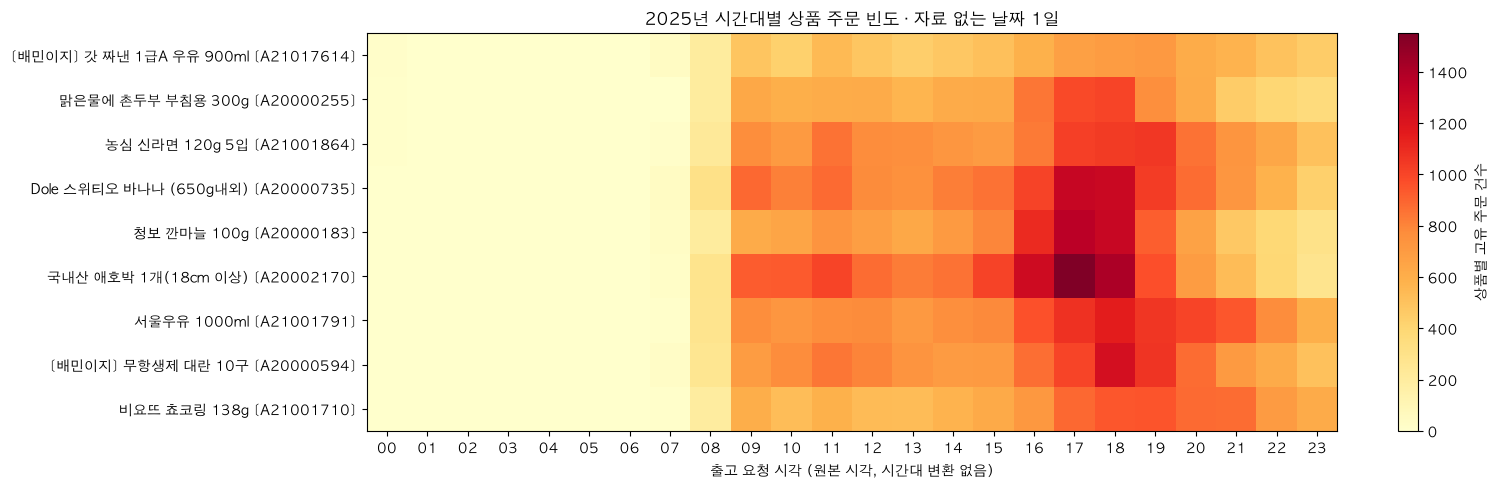

In [9]:
fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
codes = ranked.loc[ranked["rank"] <= 3, "sku_code"].drop_duplicates()
names = ranked.drop_duplicates("sku_code").set_index("sku_code")["sku_name"]
values = ranked.pivot(index="sku_code", columns="hour", values="order_count")
values = values.reindex(index=codes, columns=range(24)).fillna(0)
fig, ax = plt.subplots(figsize=(16, max(5, len(codes) * 0.5)))
plot = ax.imshow(values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(24), [f"{hour:02d}" for hour in range(24)])
ax.set_yticks(range(len(codes)), [f"{names[sku]} [{sku}]" for sku in codes])
ax.set(
    xlabel="출고 요청 시각 (원본 시각, 시간대 변환 없음)",
    title="2025년 시간대별 상품 주문 빈도 · 자료 없는 날짜 "
    + str(len(quality["missing_dates"]))
    + "일",
)
fig.colorbar(plot, ax=ax, label="상품별 고유 주문 건수")
fig.tight_layout()
plt.show()

## 9. Excel·CSV·그래프·요약 저장

`reports/hourly_2025/`의 동일 이름 파일을 갱신합니다. 전체 순위 Excel은 저장에 시간이 걸릴 수 있습니다.


In [10]:
for name, frame in (
    ("hourly_all_products", ranked),
    ("hourly_top10", top10),
    ("hourly_summary", hourly),
):
    frame.to_csv(output / f"{name}.csv", index=False, encoding="utf-8-sig")

with pd.ExcelWriter(output / "hourly_products_2025.xlsx") as writer:
    top10.to_excel(writer, sheet_name="시간별_TOP10", index=False)
    ranked.to_excel(writer, sheet_name="전체_상품_순위", index=False)
    hourly.to_excel(writer, sheet_name="시간별_전체주문", index=False)
    pd.DataFrame({"항목": list(quality), "값": [str(v) for v in quality.values()]}).to_excel(
        writer, sheet_name="데이터_점검", index=False
    )

(output / "data_quality.json").write_text(
    json.dumps(quality, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)

fig.savefig(output / "hourly_top_products.png", dpi=160)

lines = [
    "# 2025년 출고 요청 시간별 자주 출고된 상품",
    "",
    "시간: outboundRequestDateTime의 시(hour). 실제 출고 완료 시각이 아닙니다.",
    "원본에 시간대 정보가 없어 시간대 변환 없이 사용했습니다.",
    "대상: 2025년, SHIPPED, pickingQuantity > 0, 주문번호·SKU가 있는 행.",
    "빈도: 시간대·SKU별 고유 주문번호 수. 분할 행은 주문 수에서 중복 계산하지 않습니다.",
    "수량: 대상 행의 pickingQuantity 합계. 동률은 수량 내림차순, SKU 오름차순입니다.",
    "비중: 해당 상품 주문 수 / 해당 시간대 전체 고유 주문 수. "
    "상품 간 합은 100%를 넘을 수 있습니다.",
    "주문 하나가 여러 시간에 나타나면 각 시간에 집계됩니다. "
    "시간별 합과 연간 고유 주문 수는 다를 수 있습니다.",
    f"자료 없는 날짜: {', '.join(quality['missing_dates']) or '없음'}. 무출고로 단정하지 않습니다.",
    "",
    "| 시간 | 전체 주문 | 1위 (주문 수) | 2위 (주문 수) | 3위 (주문 수) |",
    "|---|---:|---|---|---|",
]

for row in hourly.itertuples():
    top = ranked[(ranked["hour"] == row.hour) & (ranked["rank"] <= 3)]
    products = [f"{r.sku_name} ({r.order_count:,})" for r in top.itertuples()]
    products += ["—"] * (3 - len(products))
    lines.append(
        f"| {row.hour:02d}:00–{row.hour:02d}:59 | {row.total_orders:,} | "
        + " | ".join(products)
        + " |"
    )

report = "\n".join(lines) + "\n"

(output / "summary.md").write_text(report, encoding="utf-8")

display(Markdown(report))
print("저장 완료:", output)
for path in sorted(output.iterdir()):
    if path.is_file():
        print(f"  {path.name} ({path.stat().st_size / 1e6:.2f} MB)")

# 2025년 출고 요청 시간별 자주 출고된 상품

시간: outboundRequestDateTime의 시(hour). 실제 출고 완료 시각이 아닙니다.
원본에 시간대 정보가 없어 시간대 변환 없이 사용했습니다.
대상: 2025년, SHIPPED, pickingQuantity > 0, 주문번호·SKU가 있는 행.
빈도: 시간대·SKU별 고유 주문번호 수. 분할 행은 주문 수에서 중복 계산하지 않습니다.
수량: 대상 행의 pickingQuantity 합계. 동률은 수량 내림차순, SKU 오름차순입니다.
비중: 해당 상품 주문 수 / 해당 시간대 전체 고유 주문 수. 상품 간 합은 100%를 넘을 수 있습니다.
주문 하나가 여러 시간에 나타나면 각 시간에 집계됩니다. 시간별 합과 연간 고유 주문 수는 다를 수 있습니다.
자료 없는 날짜: 2025-08-31. 무출고로 단정하지 않습니다.

| 시간 | 전체 주문 | 1위 (주문 수) | 2위 (주문 수) | 3위 (주문 수) |
|---|---:|---|---|---|
| 00:00–00:59 | 163 | [배민이지] 갓 짜낸 1급A 우유 900ml (14) | 맑은물에 촌두부 부침용 300g (8) | 농심 신라면 120g 5입 (7) |
| 01:00–01:59 | 0 | — | — | — |
| 02:00–02:59 | 0 | — | — | — |
| 03:00–03:59 | 0 | — | — | — |
| 04:00–04:59 | 0 | — | — | — |
| 05:00–05:59 | 0 | — | — | — |
| 06:00–06:59 | 0 | — | — | — |
| 07:00–07:59 | 733 | [배민이지] 갓 짜낸 1급A 우유 900ml (39) | Dole 스위티오 바나나 (650g내외) (39) | 청보 깐마늘 100g (34) |
| 08:00–08:59 | 6,509 | Dole 스위티오 바나나 (650g내외) (305) | 국내산 애호박 1개(18cm 이상) (279) | 서울우유 1000ml (274) |
| 09:00–09:59 | 17,810 | 국내산 애호박 1개(18cm 이상) (925) | Dole 스위티오 바나나 (650g내외) (887) | 농심 신라면 120g 5입 (767) |
| 10:00–10:59 | 17,792 | 국내산 애호박 1개(18cm 이상) (927) | Dole 스위티오 바나나 (650g내외) (814) | [배민이지] 무항생제 대란 10구 (775) |
| 11:00–11:59 | 19,456 | 국내산 애호박 1개(18cm 이상) (1,004) | Dole 스위티오 바나나 (650g내외) (883) | 농심 신라면 120g 5입 (857) |
| 12:00–12:59 | 19,051 | 국내산 애호박 1개(18cm 이상) (875) | [배민이지] 무항생제 대란 10구 (802) | 서울우유 1000ml (777) |
| 13:00–13:59 | 18,165 | 국내산 애호박 1개(18cm 이상) (824) | 농심 신라면 120g 5입 (760) | Dole 스위티오 바나나 (650g내외) (755) |
| 14:00–14:59 | 18,989 | 국내산 애호박 1개(18cm 이상) (860) | Dole 스위티오 바나나 (650g내외) (823) | 서울우유 1000ml (760) |
| 15:00–15:59 | 20,340 | 국내산 애호박 1개(18cm 이상) (1,007) | Dole 스위티오 바나나 (650g내외) (855) | 청보 깐마늘 100g (795) |
| 16:00–16:59 | 24,383 | 국내산 애호박 1개(18cm 이상) (1,269) | 청보 깐마늘 100g (1,101) | Dole 스위티오 바나나 (650g내외) (1,011) |
| 17:00–17:59 | 28,803 | 국내산 애호박 1개(18cm 이상) (1,551) | 청보 깐마늘 100g (1,359) | Dole 스위티오 바나나 (650g내외) (1,303) |
| 18:00–18:59 | 30,668 | 국내산 애호박 1개(18cm 이상) (1,410) | 청보 깐마늘 100g (1,300) | Dole 스위티오 바나나 (650g내외) (1,295) |
| 19:00–19:59 | 28,536 | [배민이지] 무항생제 대란 10구 (1,062) | 서울우유 1000ml (1,057) | 농심 신라면 120g 5입 (1,051) |
| 20:00–20:59 | 25,542 | 서울우유 1000ml (1,001) | 비요뜨 쵸코링 138g (881) | Dole 스위티오 바나나 (650g내외) (876) |
| 21:00–21:59 | 22,474 | 서울우유 1000ml (944) | 비요뜨 쵸코링 138g (875) | 농심 신라면 120g 5입 (728) |
| 22:00–22:59 | 19,926 | 서울우유 1000ml (771) | 비요뜨 쵸코링 138g (698) | 농심 신라면 120g 5입 (638) |
| 23:00–23:59 | 16,687 | 비요뜨 쵸코링 138g (612) | 서울우유 1000ml (595) | 농심 신라면 120g 5입 (508) |


저장 완료: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/hourly_2025
  data_quality.json (0.00 MB)
  hourly_all_products.csv (14.05 MB)
  hourly_products_2025.xlsx (10.61 MB)
  hourly_summary.csv (0.00 MB)
  hourly_top10.csv (0.01 MB)
  hourly_top_products.png (0.12 MB)
  summary.md (0.00 MB)


분석을 마쳤으면 커널을 종료해 메모리를 해제하세요. 집계를 다시 계산하려면 2번 셀부터 순서대로 실행하거나 **Restart Kernel and Run All Cells**를 사용하세요.
